# 03 Turn every wafer into 14 numbers

A model needs a table: one row per wafer, one column per number. I could give it all 2704 squares, but then a
Center that sits two squares to the left looks like a new pattern. So I measure **where** chips failed instead:

- the share of failed chips on the whole wafer
- the share in 5 rings, from the middle to the edge
- the share in 8 slices around the middle

These 14 numbers are the **features**. The functions for them are in `wafer.py`.

Saves `output/features.npz`.

## 1. The rings and the slices

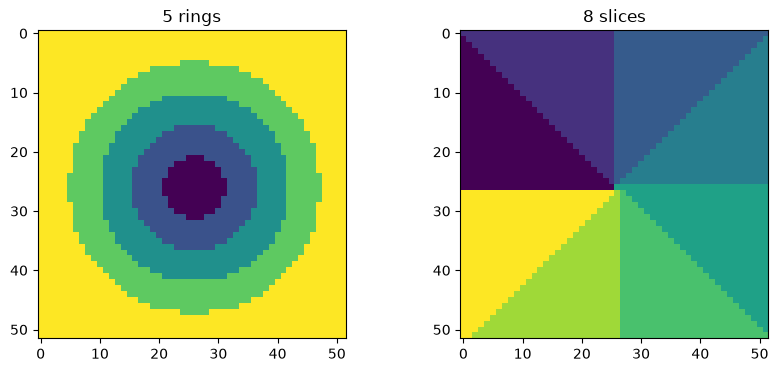

In [1]:
from random import random

import numpy as np
import matplotlib.pyplot as plt

import wafer

# RING and SLICE are 52x52 like a wafer. every square has the number of its ring (0 middle - 4 edge)
# or its slice (0-7, like a pizza). made once in wafer.py so every wafer gets measured the same way
plt.figure(figsize=(10, 4)) # width, height in inches

plt.subplot(1, 2, 1) # 1 row 2 pics, this is the left one
plt.imshow(wafer.RING) # every ring number gets its own colour
plt.title("5 rings")

plt.subplot(1, 2, 2)
plt.imshow(wafer.SLICE)
plt.title("8 slices")

plt.show()

## 2. Check it on one wafer

A Center wafer should have a high `ring_0` (the middle) and low numbers at the edge.

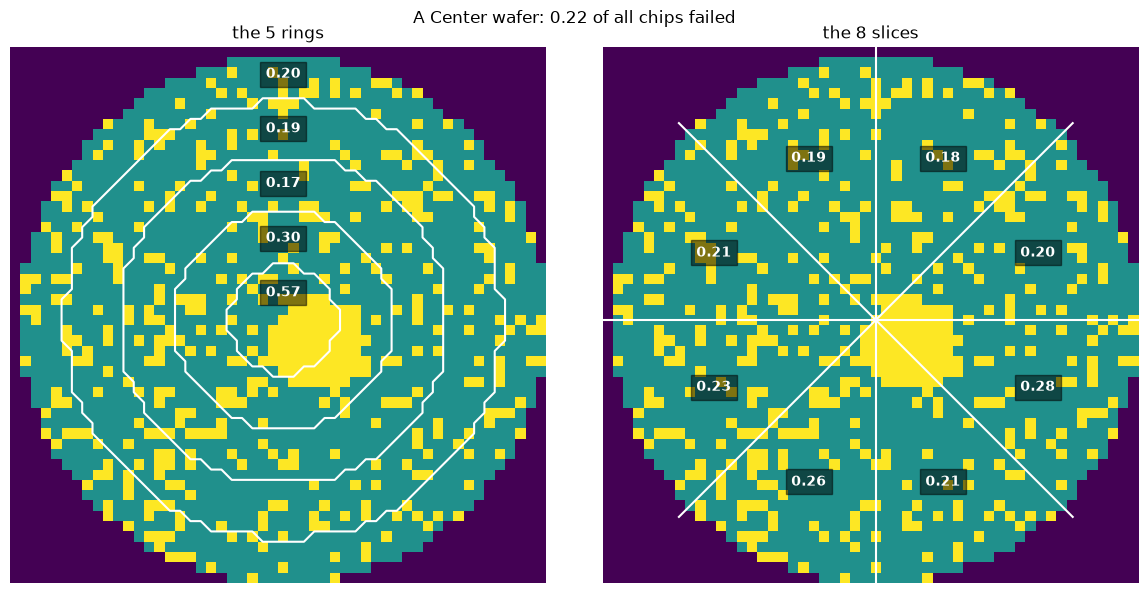

In [2]:
split = np.load("output/split.npz") # made in 02
maps_train = split["maps_train"] # (25823, 52, 52)
y_train = split["y_train"] # (25823, 8)

# find a wafer with only Center. all(axis=1) = all 8 match, np.where gives the positions in a tuple so [0],
# the last [0] = just the first one
center = np.where((y_train == [1, 0, 0, 0, 0, 0, 0, 0]).all(axis=1))[0][0]

# its 14 numbers: [0] whole wafer, [1]-[5] the rings, [6]-[13] the slices
numbers = wafer.features(maps_train[center])

plt.figure(figsize=(12, 6))

# left: the rings with their number in them
plt.subplot(1, 2, 1)
plt.imshow(maps_train[center])

# contour draws lines where RING goes from 0 to 1, 1 to 2 etc, so the ring borders
plt.contour(wafer.RING, levels=[0.5, 1.5, 2.5, 3.5], colors="white")

slices = 14

for k in range(5):
    # radius 26.5 / 5 rings = 5.3 per ring, +0.5 to get the middle of ring k
    middle_of_ring = (k + 0.5) * 26.5 / 5

    # text(x, y, text). 26 ... so it goes up from the middle (row 0 is the top)
    # ha/va = center the text on that spot, bbox = the dark box behind it so you can read it
    plt.text(26, 26 - middle_of_ring, f"{numbers[1 + k]:.2f}", color="white", ha="center", va="center",
             fontweight="bold", bbox={"facecolor": "black", "alpha": 0.5})
plt.title("the 5 rings")
plt.axis("off")

# right: the slices with their number in them
plt.subplot(1, 2, 2)
plt.imshow(maps_train[center])
for k in range(8):
    # the angle where slice k starts. radians because cos and sin dont take degrees
    border = np.radians(-180 + 45 * k) # slice 0 starts at -180, every slice is 45 wide
    # line from the middle 27 squares out, cos = how far sideways, sin = how far down
    plt.plot([26, 26 + 27 * np.cos(border)], [26, 26 + 27 * np.sin(border)], color="white")

    # half a slice further (22.5 degrees) is the middle, put the number there 17 squares out
    middle_of_slice = border + np.radians(22.5)
    plt.text(26 + 17 * np.cos(middle_of_slice), 26 + 17 * np.sin(middle_of_slice), f"{numbers[6 + k]:.2f}",
             color="white", ha="center", va="center", fontweight="bold", bbox={"facecolor": "black", "alpha": 0.5})

# the lines make the plot bigger than the picture, this cuts it back to the wafer
plt.xlim(-0.5, 51.5)
plt.ylim(51.5, -0.5) # upside down because row 0 is at the top
plt.title("the 8 slices")
plt.axis("off")

plt.suptitle(f"A Center wafer: {numbers[0]:.2f} of all chips failed") # 1 title over both
plt.tight_layout()
plt.show()

**What to look for:** the middle ring has the highest number and the outer rings are low. The 8 slices differ
much less than the rings, because a Center is in the middle and not on one side. The slices where the blob
sits a bit off the middle are a little higher.

## 3. The table for every wafer

`wafer.features()` for every wafer in every part. This takes a little while.

In [3]:
# features() for every wafer, np.array makes it a table: 1 row per wafer, 14 columns. takes a while
X_train = np.array([wafer.features(m) for m in maps_train])
X_val = np.array([wafer.features(m) for m in split["maps_val"]])
X_test = np.array([wafer.features(m) for m in split["maps_test"]])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (25823, 14)
Validation: (5533, 14)
Test: (5534, 14)


**What to look for:** 14 columns in every part.

## 4. Save

In [4]:
# X = the 14 numbers (input), y = the labels (answer). row i in X still goes with row i in y
np.savez_compressed("output/features.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=split["y_val"],
                    X_test=X_test, y_test=split["y_test"])
print("Saved output/features.npz")

Saved output/features.npz
